Linear Regression

importing libraries

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [14]:
df = pd.read_csv('student.csv')
df.head()

,Student_ID,Study_Hours,Exam_Score
0,STU_1000,4.2,48
1,STU_1001,9.1,88
2,STU_1002,7.2,74
3,STU_1003,6.1,53
4,STU_1004,2.3,30


In [15]:
df.shape

(100, 3)

<Axes: title={'center': 'Study Hours vs Marks'}, xlabel='Study_Hours', ylabel='Exam_Score'>

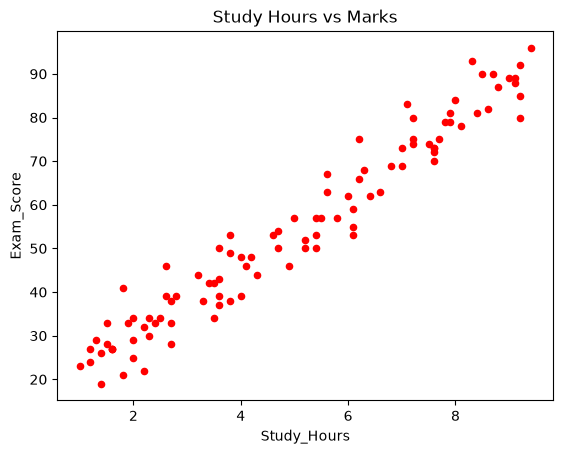

In [17]:
df.plot.scatter(x= 'Study_Hours', y= 'Exam_Score', title= 'Study Hours vs Marks', color= 'red')

Data Preprocessing

In [21]:
# Prepare the data to 2-D array for the model

y = df['Exam_Score'].values.reshape(-1, 1) 
x = df['Study_Hours'].values.reshape(-1, 1)
y.shape

(100, 1)

In [23]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [24]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(80, 1) (20, 1) (80, 1) (20, 1)


Training a Linear Regression Model

In [25]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()

In [26]:
regressor.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[8.24]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[13.09]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[22.13]


In [27]:
print(regressor.intercept_)
print(regressor.coef_)

[13.08931116]
[[8.23626]]


Making Predictions


In [28]:
def calc(slope, intercept, hours):
    return slope*hours+intercept

score = calc(regressor.coef_, regressor.intercept_, 9.5)
print(score) 

[[91.33378119]]


In [29]:
score = regressor.predict([[9.5]])
print(score) 

[[91.33378119]]


Testing

In [30]:
y_pred = regressor.predict(X_test)

In [31]:
df_preds = pd.DataFrame({'Actual': y_test.squeeze(), 'Predicted': y_pred.squeeze()})
print(df_preds)

    Actual  Predicted
0       28  25.443701
1       82  83.921147
2       70  75.684887
3       63  67.448627
4       44  39.445343
5       54  51.799733
6       42  41.916221
7       93  81.450269
8       27  22.972823
9       48  47.681603
10      50  51.799733
11      75  64.154123
12      81  78.155765
13      89  88.039277
14      34  29.561831
15      30  32.032709
16      73  75.684887
17      27  26.267327
18      78  79.803017
19      33  32.856335


Evaluating the Model


In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


In [33]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

In [34]:
print(f'Mean absolute error: {mae:.2f}')
print(f'Mean squared error: {mse:.2f}')
print(f'Root mean squared error: {rmse:.2f}')

Mean absolute error: 3.28
Mean squared error: 20.12
Root mean squared error: 4.49
